In [1]:
import sys
import os
# get absolute path to project root
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

if project_root not in sys.path:
    sys.path.append(project_root)

print("Project root added:", project_root)

Project root added: c:\Users\Ernesto Pérez\Documents\Git\yaluk_network_lib


In [2]:
import Network_lib as nl
import pandas as pd
from Network_lib.Node import PhaseName
import Lightning_lib as ls



In [3]:

solver_dir = r"C:\EMTP\Solver"
os.environ["PATH"] = solver_dir + os.pathsep + os.environ["PATH"]

In [4]:
import shutil

print(os.path.exists(r"C:\EMTP\Solver"))
print(os.path.exists(r"C:\EMTP\Solver\tp_yaluk.exe"))
print(shutil.which("tp_yaluk.exe"))
print(shutil.which("tpyaluk.exe"))

True
True
C:\EMTP\Solver\tp_yaluk.exe
None


In [5]:
class Trf_parameters():
        def __init__(self,A,B,C,D):
            self.CapHV=A
            self.CapHL=B
            self.CapLV=C
            self.Ground=D

In [6]:
def data_setting():
    #Definition Nodes
    #id of the node must be integer or string of maximum 4 characters, preferably integer, label is the name of the node, x and y are the coordinates in meters from the initial location defined in the network_setting function, if ctype is "rel" the coordinates are relative to the initial location, if ctype is "abs" the coordinates are absolute from the initial location
    Nodes = pd.DataFrame(columns=['id', 'label','y','x'])
    Nodes.loc[0] = [1, 'N1', 125300, 103000]
    Nodes.loc[1] = [2, 'N2', 125450, 103050]
    Nodes.loc[2] = [3, 'N3', 125550, 103100]
    Nodes.loc[3] = [4, 'N4', 125650, 103150]
    Nodes.loc[4] = [5, 'N5', 125750, 103200]
    Nodes.loc[5] = [6, 'N6', 125850, 103250]
    Nodes.loc[6] = [7, 'N7', 125950, 103400]
    Nodes.loc[7] = [8, 'N8', 125450, 103150]
    Nodes.loc[8] = [9, 'N9', 126000, 103400]
    Nodes.loc[9] = [10, 'N10', 126150, 103450]

    #Definition Lines
    "from_node to to_node must be the id of the nodes defined in the Nodes dataframe, configuration_type must be one of the configurations defined in the network_setting function"
    Lines=pd.DataFrame(columns=['id', 'label', 'from_node', 'to_node','configuration_type'])
    Lines.loc[0] = [1, 'L1', 'N1', 'N2','Config_A']
    Lines.loc[1] = [2, 'L2', 'N2', 'N3','Config_A']
    Lines.loc[2] = [3, 'L3', 'N3', 'N4','Config_B']
    Lines.loc[3] = [4, 'L4', 'N4', 'N5','Config_B']
    Lines.loc[4] = [5, 'L5', 'N5', 'N6','Config_B']
    Lines.loc[5] = [6, 'L6', 'N6', 'N7','Config_B']
    Lines.loc[6] = [7, 'L7', 'N4', 'N8','Config_B']
    Lines.loc[7] = [8, 'L8', 'N5', 'N9','Config_B']
    Lines.loc[8] = [9, 'L9', 'N6', 'N10','Config_B']

    #Cables Definition
    Cables=pd.DataFrame(columns=['id', 'label', 'radio', 'resistance','description'])
    Cables.loc[0] = ['ACSR_2/0','Cable ACSR_2/0', .005, 1, 'Conductor Calibre 2/0 - catálogo CENTELSA']
    Cables.loc[1] = ['AAAC_1/0', 'Cable AAAC_1/0', .004, 0.8, 'Conductor Calibre 1/0 - catálogo CENTELSA']

    #Line Configuration Definition
    Config_types=pd.DataFrame(columns=['id', 'name','description', 'Geometry'])
    Config_types.loc[0] = ['Config_A','Config LAR201', 'Linea dos fases', "[['ACSR_2/0',10,0],['ACSR_2/0',10,2]]"]
    Config_types.loc[1] = ['Config_B', 'Config LAR202', 'Linea una fase', "[['ACSR_2/0',10,0]]"]
    Config_types.loc[2] = ['Config_C', 'Config LAR203', 'Linea tres fases', "[['AAAC_1/0',10,0],['AAAC_1/0',10,2],['AAAC_1/0',10,4]]"]
    Config_types.loc[3] = ['Config_D', 'Config LAR204', 'Linea tres fases y Guarda', "[['AAAC_1/0',10,0],['AAAC_1/0',10,2],['AAAC_1/0',10,4],['AAAC_1/0',12,0]]"]

    #Transformers connections
    Transformers=pd.DataFrame(columns=['id', 'label', 'from_node', 'phases','trf_type'])
    Transformers.loc[0] = [1, 'T1', 'N2', 111,'Tr1']
    Transformers.loc[1] = [2, 'T2', 'N1', 11,'Tr2']
    Transformers.loc[2] = [3, 'T3', 'N3', 101,'Tr1']
    #Transformers Types

    Trftype=pd.DataFrame(columns=['id', 'CHV', 'CLV', 'CHL', 'ground'])
    Trftype.loc[0] = ['Tr1', 340e-12, 215e-12, 744e-12,10.0]
    Trftype.loc[1] = ['Tr2', 440e-12, 115e-12, 644e-12,20.0]


    #surge arresters
    #Surge_Arresters=pd.read_csv('surge_arresters.csv')
    Surge_Arresters=pd.DataFrame(columns=['id', 'label', 'node', 'phases','file'])
    Surge_Arresters.loc[0] = [1, 'SA1', 'N2',111,'SAIEEE_3ph.pch']
    Surge_Arresters.loc[1] = [2, 'SA2', 'N3',1,'saieee_15kV_1ph.pch']
    return Nodes, Lines, Transformers, Surge_Arresters, Trftype, Cables, Config_types


### Definición de datos

In [7]:
print("Starting network creation...")
Nodes,Lines,Transformers,Surge_Arresters,Trftype,Cables,Config_types = data_setting()
print(Config_types)
print("Data setting completed.")


Starting network creation...
         id           name                description  \
0  Config_A  Config LAR201            Linea dos fases   
1  Config_B  Config LAR202             Linea una fase   
2  Config_C  Config LAR203           Linea tres fases   
3  Config_D  Config LAR204  Linea tres fases y Guarda   

                                            Geometry  
0              [['ACSR_2/0',10,0],['ACSR_2/0',10,2]]  
1                                [['ACSR_2/0',10,0]]  
2  [['AAAC_1/0',10,0],['AAAC_1/0',10,2],['AAAC_1/...  
3  [['AAAC_1/0',10,0],['AAAC_1/0',10,2],['AAAC_1/...  
Data setting completed.


### CREAR RED

Si los datos provienen de archivos csv usar:

In [8]:
print("Creating network from csv data...")
#Si los datos de entrada están definidos en archivos csv usar:
# net=nl.network_setting(Nodes_csv="Nodes.csv",
#                        Lines_csv="Lines.csv",
#                        Transformers_csv="Transformers.csv",
#                        Surge_Arresters_csv="Surge_Arresters.csv",
#                        Trftype_csv="Trftype.csv",
#                        Cables_csv="Cables.csv",
#                        Config_types_csv="Config_types.csv", 
#                        name_net="Example_Network") 

Creating network from csv data...


Si los datos provienen de un dataframe usar:

In [9]:
print("Creating network from dataframes...")
net=nl.network_setting(Nodes=Nodes,
                    Lines=Lines,
                    Transformers=Transformers,
                    Surge_Arresters=Surge_Arresters,
                    Trftype=Trftype,
                    Cables=Cables,
                    Config_types=Config_types,
                    name_net="Example_Network")
print("Network created successfully.")

Creating network from dataframes...
Creating network with 10 nodes, 9 lines, 3 transformers, 
          2 surge arresters, 2 cables, and 4 line configurations.
Initializing network...
Network created successfully.


Creando datos de rayo específico

In [ ]:
print("Creating lightning object...")
Li_ds=ls.Lightning()
Li_ds.initlocation=net.InitLatLong
Li_ds.Location_x=300 #[m]
Li_ds.Location_y=20 #[m]
Li_ds.Ih1=40e3 #[A] Imax
Li_ds.tf1=2e-6 #[s] Tiempo de subida
Li_ds.tc1=5e-5 #[s] Tiempo de caída
Li_ds.n1=2 # Constante de forma función Heidler
print("Lightning object created successfully.")

Creating lightning object...
Lightning object created successfully.


Creación archivos configruación

In [11]:
import Project_lib as yp 

SimulationSettins_df = pd.DataFrame(columns=['Conductivity', 'Permitivity', 'Dx', 'Typewaveform', 'MaxDistCamp','Print_field','Print_field_info','Read_field','Status_profile'])
SimulationSettins_df.loc[0] = [100.0, 10.0, 10.0, 1, 10000.0, False, False, False, False]

Channel_settings_df = pd.DataFrame(columns=['Velocity', 'Atenuation_const', 'Heigth'])
Channel_settings_df.loc[0] = [2.99e8, 1e-6, 5000]

Soil_settings_df = pd.DataFrame(columns=['Conductivity', 'Permitivity', 'Perfectsoil'])
Soil_settings_df.loc[0] = [100.0, 10.0, False]

Atp_settings_df = pd.DataFrame(columns=['printfreq','plotfreq','pl4out','NetwrkOut','SSPhasor','MaxMinOut','MemSave','ExtrPinOut'])
Atp_settings_df.loc[0] = [999999, 1, 1, 1, 1, 1, 0, 0]


In [12]:
proj_settings=yp.setup_settings(SimulationSettins_df, Channel_settings_df, Soil_settings_df, Atp_settings_df)

Project settings setup completed.


# CREACION ATP y ARCHIVOS EJECUCION

Se crea un proyecto para una red y un rayo específico con las configuraciones dadas

In [13]:
import Project_lib.proj_functions as pf
pf.create_project_files(proj_settings, net, Li_ds,
                        solver_cwd=r"C:\EMTP\Solver", 
                        solver_path=r"C:\EMTP\Solver\tp_yaluk.exe")


* Impacto indirecto.
  Distancia mínima al punto de impacto: 200.00 m
  Tensión de Rusck máximo calculado: 77.75 kV
  Línea más cercana al punto de impacto: 
Número de líneas FDTD en la red: 9: 9
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_001.dat s -r
Short path: Example_Network\lcc\lcc_001.lib
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_001.dbm s -r
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_002.dat s -r
Short path: Example_Network\lcc\lcc_002.lib
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_002.dbm s -r
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_003.dat s -r
Short path: Example_Network\lcc\lcc_003.lib
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_003.dbm s -r
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_004.dat s -r
Short path: Example_Network\lcc\lcc_004.lib
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_004.dbm s -r
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_005.dat s -r
Short path: Example_Netwo

In [14]:
for l in net.Lines:
    print(l.id,l.length)


Line 001 158.11388300841898
Line 002 111.80339887498948
Line 003 111.80339887498948
Line 004 111.80339887498948
Line 005 111.80339887498948
Line 006 180.27756377319946
Line 007 200.0
Line 008 320.1562118716424
Line 009 360.5551275463989


In [15]:
from Network_lib.atp_solver import run_atp_file
from pathlib import Path

file_name=Path(net.name)/f"{net.name}.atp"
run_atp_file(
    file_name,
    solver_path=r"C:\EMTP\Solver\tp_yaluk.exe",
    keep_pl4=True,
)

Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH Example_Network.atp s -r


CompletedProcess(args=['C:\\EMTP\\Solver\\tp_yaluk.exe', 'BOTH', 'Example_Network.atp', 's', '-r'], returncode=0, stdout='                                 ATP Started at 15:42:37 on Friday,  8 May 2026\n  After MAIN0A.  Debug file name  CLIKL2 =debug001.tmp \n   ---   275   cards of disk file read into card cache cells  1   onward.\n Note:  Vardim input  LISTSIZE.DAT  could not be connected.  Use maximum sizes.\n   --- Pass 1.   Card = 239.   Ready to open $INCLUDE = surges\\SAIEEE_3ph.pch                                                       \n   --- Pass 1.   Card = 308.   Ready to open $INCLUDE = surges\\saieee_15kV_1ph.pch                                                  \n <===> Done with  "/"-card sorting by data class.    Remember that the source file appears different from interpreted input data.\nAlternative Transients Program (ATP),  Intel Visual Fortran.    All rights reserved by Can/Am user group of Portland, Oregon, USA.\n Date (dd-mth-yy) and time of day (hh.mm.ss) = 08-M

In [16]:
#Creación de archivo atp y líneas para uso en el PC local
net.MakeAtpFile(stroke=Li_ds)
net.MakeLccFile(run_solver=True,    solver_path=r"C:\EMTP\Solver\tp_yaluk.exe",
    solver_cwd=r"C:\EMTP\Solver",
)
net.MakeLineFiles(return_buffer=False)

# Devolviendo el buffer de las líneas y archivo ATP para uso en el cluster
Li_ds.Location_x=500 #[m]
buffer=net.MakeATPBuffer(stroke=Li_ds,distance_threshold=1000)
zip_buffer=net.MakeLineFiles()


* Impacto indirecto.
  Distancia mínima al punto de impacto: 200.00 m
  Tensión de Rusck máximo calculado: 77.75 kV
  Línea más cercana al punto de impacto: 
Número de líneas FDTD en la red: 9: 9
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_001.dat s -r
Short path: Example_Network\lcc\lcc_001.lib
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_001.dbm s -r
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_002.dat s -r
Short path: Example_Network\lcc\lcc_002.lib
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_002.dbm s -r
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_003.dat s -r
Short path: Example_Network\lcc\lcc_003.lib
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_003.dbm s -r
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_004.dat s -r
Short path: Example_Network\lcc\lcc_004.lib
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_004.dbm s -r
Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH lcc_005.dat s -r
Short path: Example_Netwo

### Ejecución de un archivo atp

In [17]:
from Network_lib.atp_solver import run_atp_file
run_atp_file(
    f"{net.name}.atp",
    solver_path=r"C:\EMTP\Solver\tp_yaluk.exe",
    keep_pl4=True,
)
#run_atp_file(
#    f"Example_Network2old.atp",
#   solver_path=r"C:\EMTP\Solver\tp_yaluk.exe", 
#    keep_pl4=True)

Running command: C:\EMTP\Solver\tp_yaluk.exe BOTH Example_Network.atp s -r


CompletedProcess(args=['C:\\EMTP\\Solver\\tp_yaluk.exe', 'BOTH', 'Example_Network.atp', 's', '-r'], returncode=0, stdout='                                 ATP Started at 15:42:47 on Friday,  8 May 2026\n  After MAIN0A.  Debug file name  CLIKL2 =debug001.tmp \n \n------------------------------------------------------------------------------------------------------------------------------------\nERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/\nERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/ERROR/\n------------------------------------------------------------------------------------------------------------------------------------\nYou lose, fella.   The EMTP logic has detected an error condition, and is now going to terminate program execution.  The following\nmessage summarizes the circumstances.  No input data card has yet bee

In [18]:
num_events=1000
lig_stat=ls.Lightning_stat(net,num_events,'ProbDistribution')
    
lig_stat.Create_csvDB("lightning_database.csv")


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.collections import LineCollection
import pandas as pd

def plot_lines_stylish(df:pd.DataFrame,ax=None, line_col='line_id',
                       x1='Xi', y1='Yi', x2='Xj', y2='Yj'):
    
    # Apply seaborn theme
    sns.set_theme(style="whitegrid", context="talk")
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    else:
        fig = ax.figure
    
    # Unique lines
    lines = df[line_col].unique()
    
    # Beautiful seaborn palette
    palette = sns.color_palette("tab10", len(lines))
    
    for i, (line, group) in enumerate(df.groupby(line_col)):
        segments = [
            [(xs, ys), (xe, ye)]
            for xs, ys, xe, ye in zip(group[x1], group[y1], group[x2], group[y2])
        ]
        
        lc = LineCollection(
            segments,
            colors='black',
            linewidths=2.5,
            alpha=0.9
        )
        ax.add_collection(lc)
    
    ax.autoscale()
    ax.set_aspect('equal')
    ax.set_xlabel("X coordinate")
    ax.set_ylabel("Y coordinate")
    ax.set_title("Network Line Segments")
    
    sns.despine()
    #plt.tight_layout()
    plt.show()
    return fig, ax

In [20]:
df_lig= lig_stat.create_dataframe()
net.create_dataframes()

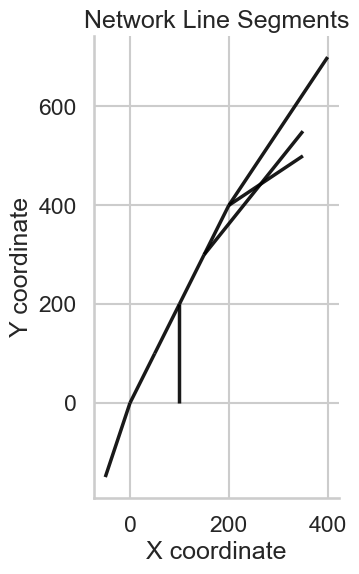

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Network Line Segments'}, xlabel='X coordinate', ylabel='Y coordinate'>)

In [21]:
plot_lines_stylish(net.df_lines, line_col='Line_id', x1='Xi', y1='Yi', x2='Xj', y2='Yj')

In [22]:
import matplotlib.pyplot as plt

def plot_strike_points(df, ax=None,
                       size_ds=4,
                       size_rsk=2,
                       size_id=4,
                       Vrusck_threshold=50):
    
    # If no axis is passed, create one
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    else:
        fig = ax.figure

    # 1️⃣ Direct strike
    df_ds1 = df[df["direct_strike"] == 1]
    ax.scatter(df_ds1["X0"], df_ds1["Y0"], s=size_ds)

    # 2️⃣ Indirect strike (>= threshold)
    df_id = df[(df["direct_strike"] == 0) &
               (df["Rusck_max_voltage"] >= Vrusck_threshold)]
    ax.scatter(df_id["X0"], df_id["Y0"], s=size_id)

    # 3️⃣ Indirect strike (< threshold)
    df_rusck = df[(df["Rusck_max_voltage"] < Vrusck_threshold) &
                  (df["direct_strike"] == 0)]
    ax.scatter(df_rusck["X0"], df_rusck["Y0"],
               s=size_rsk, c='green')

    ax.set_xlabel("X0")
    ax.set_ylabel("Y0")
    ax.set_title("Scatter Plot X0 vs Y0")

    ax.legend([
        "Direct Strike",
        f"Indirect Strike (Rusck_maxV ≥ {Vrusck_threshold} kV)",
        f"Indirect Strike (Rusck_maxV < {Vrusck_threshold} kV)"
    ])

    print(f"Number of points with direct strike = 1: {len(df_ds1)}")

    return fig, ax

Number of points with direct strike = 1: 28


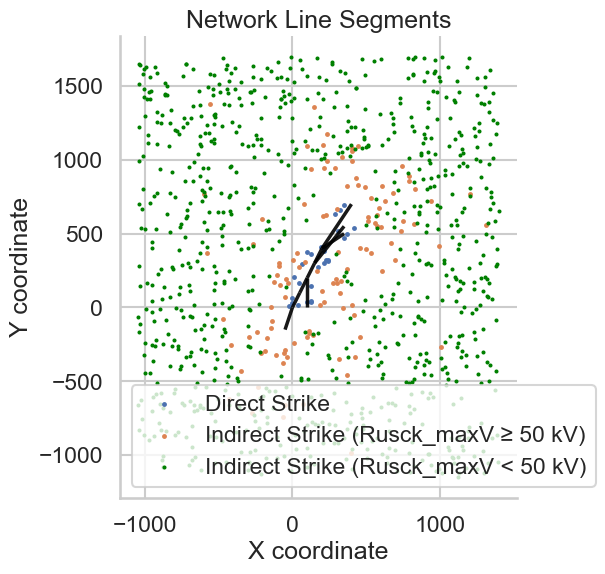

In [23]:
fig,ax =plot_strike_points(lig_stat.lightnings_df)
fig,ax=plot_lines_stylish(net.df_lines, line_col='Line_id', x1='Xi', y1='Yi', x2='Xj', y2='Yj', ax=ax)

In [24]:
display(lig_stat.lightnings_df.head())

,Ih1,Ih2,tao11,tao21,tao12,tao22,n1,n2,X0,Y0,direct_strike,min_dist,line_id_nearest,Rusck_max_voltage,Lat,Lng
0,17789.084795,0.0,1.564217e-06,0.00005,0.0,0.0,4,0,-302.406442,1095.882865,0,804.033790,None,8.600794,-113.941923,-9.833773
1,19566.609688,0.0,2.581397e-07,0.00005,0.0,0.0,4,0,894.225561,-391.247213,0,885.363554,None,8.591187,-113.935218,-9.845129
2,23095.275439,0.0,6.331523e-07,0.00005,0.0,0.0,4,0,1334.512302,1389.420273,0,1161.298220,None,7.731052,-113.930367,-9.833432
3,73686.522340,0.0,4.860076e-06,0.00005,0.0,0.0,4,0,508.158874,-958.943701,0,982.818010,None,29.145679,-113.938454,-9.848608
4,29915.075635,0.0,2.166402e-06,0.00005,0.0,0.0,4,0,-813.982703,273.095499,0,858.573813,None,13.544772,-113.946283,-9.838863


KeyError: 'Rusck_maxV'

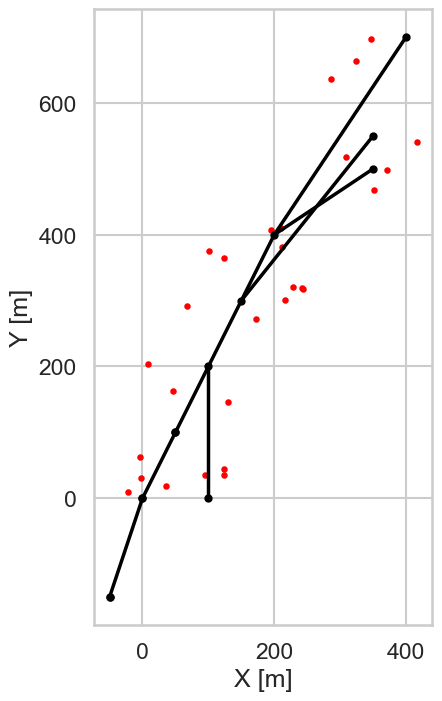

In [25]:
import matplotlib.pyplot as plt
from plot_lib.plotylk import plot_lightnings, plot_lines, plot_nodes

fig, ax = plt.subplots(figsize=(10, 8))

plot_lines(net.df_lines, coord_type="car", ax=ax)
plot_nodes(net.df_nodes, coord_type="car", ax=ax)
plot_lightnings(lig_stat.lightnings_df,
                coord_type="car",
                mode="categorical",
                ax=ax)

plt.show()

In [ ]:
import numpy as np
Ih = df["Ih1"]
Ih = Ih[Ih > 0]

# Crear bins logarítmicos
bins = np.logspace(np.log10(Ih.min()),
                   np.log10(Ih.max()),
                   50)

plt.figure()

plt.hist(Ih, bins=bins, density=True)

plt.xscale("log")
plt.yscale("linear")

plt.xlabel("Ih")
plt.ylabel("Density")
plt.title("Ih Distribution (log-log)")
plt.grid(True, which="both")

plt.show()

NameError: name 'df' is not defined

In [ ]:
Ih_sorted = np.sort(Ih)

# Probabilidad acumulada empírica
N = len(Ih_sorted)
cdf = np.arange(1, N+1) / N

plt.figure()

plt.plot(Ih_sorted, cdf)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Ih")
plt.ylabel("Cumulative Probability")
plt.title("Ih CDF (log-log)")
plt.grid(True, which="both")

plt.show()

NameError: name 'Ih' is not defined

In [ ]:
import ctypes
from ctypes import wintypes

def get_short_path(long_path):
    import ctypes
    from ctypes import wintypes
    buffer = ctypes.create_unicode_buffer(260)
    ctypes.windll.kernel32.GetShortPathNameW(
        long_path,
        buffer,
        260
    )
    return buffer.value

def run_atp(file:str):
    import subprocess
    import os

    file=get_short_path(file)
    print(f"Using short path: {file}")
    # Comando para ejecutar el programa externo
    current_dir = os.getcwd()
    #os.chdir("C:\\EMTP\\Solver\\")
    print(os.getcwd())
    #print(os.listdir())
    file_out = file.replace(".dat", ".lis")
    command = f"C:\\EMTP\\Solver\\tpbigm.exe BOTH {file} s -R"
    print(f"Running command: {command}")
    try:
        # Ejecutar el comando
        result = subprocess.run(command, 
                                shell=True, 
                                cwd=r"C:\\EMTP\\Solver\\",
                                check=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
        print("Programa ejecutado exitosamente.")
        print("Salida:", result.stdout.decode())
    except subprocess.CalledProcessError as e:
        print("Error al ejecutar el programa.")
        print("Código de error:", e.returncode)
        print("Mensaje de error:", e.stderr.decode())

In [ ]:
file="C:\\Users\\Ernesto Pérez\\Documents\\Git\\yaluk_network_lib\\lcc\\lcc_001.dat"
run_atp(file)

Using short path: C:\Users\ERNEST~1\DOCUME~1\Git\YALUK_~2\lcc\lcc_001.dat
c:\Users\Ernesto Pérez\Documents\Git\yaluk_network_lib
Running command: C:\EMTP\Solver\tpbigm.exe BOTH C:\Users\ERNEST~1\DOCUME~1\Git\YALUK_~2\lcc\lcc_001.dat s -R
Error al ejecutar el programa.
Código de error: 3
Mensaje de error: open: No such file or directory
apparent state: unit 46 named C:\Users\ERNEST,1\DOCUME,1\Git\YALUK_,                 .dbg
last format: list io
lately writing sequential formatted external IO

